# Reflection profiles from Julia time-domain data

Run the setup cell and then the figure cell. The existing CSV files for $\Delta t = 1, 2, 2.5, 2.8$ are combined into one row with a shared legend. The vector PDF follows the reference paper layout, with individual axis labels and a shared legend below the plots, for insertion at full text width on A4.

Layout reference: [coincidence_vs_frequency_results.ipynb](https://github.com/rpiron/calibration_twophoton_waveguideQED/blob/main/notebooks/coincidence_vs_frequency_results.ipynb).

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().resolve()
for candidate in (project_root, *project_root.parents):
    if (candidate / "timedomain_cross_validation/jl_src/reflection.jl").is_file():
        project_root = candidate
        break
else:
    raise FileNotFoundError("Run this notebook from the repository or one of its subdirectories.")
PROJECT_DIR = project_root / "timedomain_cross_validation"

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "lines.linewidth": 1.0,
    "lines.markersize": 4,
})
pi = np.pi
RESOLUTION = 300

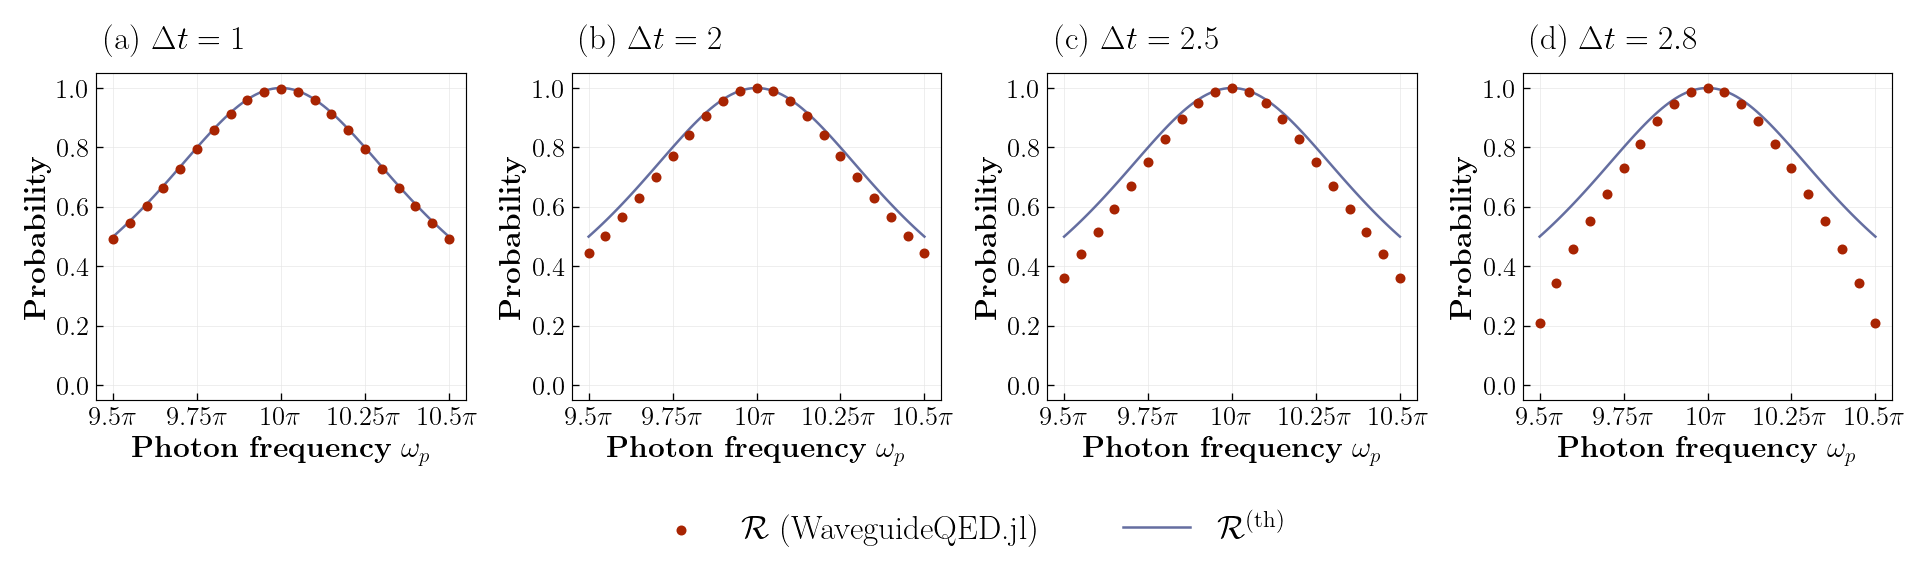

In [2]:
import sys
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.plot_fonts import paper_fonts

# One cell = one full-width figure for the four selected Julia time steps.
CSV_DIR = PROJECT_DIR / "results/csv"
FIG_DIR = PROJECT_DIR / "results/fig"
FIG_DIR.mkdir(parents=True, exist_ok=True)
time_steps = [1, 2, 2.5, 2.8]
# The simulation is in a rotating frame; these parameters restore the absolute frequency axis.
param_cavity = {"omega_A": 10*pi, "gamma_A": pi, "L": 100}
omega_A, gamma_A = param_cavity['omega_A'], param_cavity['gamma_A']
frequency_tab_theory = np.linspace(omega_A - gamma_A/2, omega_A + gamma_A/2, 100)
R_theory = 1 / (1 + ((frequency_tab_theory - omega_A) / (gamma_A/2))**2)

# Layout of the reference paper: individual axes, one-line panel labels, legend below.
# Font sizes account for reduction to approximately 18 cm in the article.
fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=RESOLUTION)

for panel_index, (ax, dt) in enumerate(zip(axes, time_steps)):
    df = pd.read_csv(CSV_DIR / f"reflection_profile_jl_dt_{dt:g}.csv")
    if not np.allclose(df['dt'], dt):
        raise ValueError(f"The time step in the CSV does not match dt={dt}.")
    photon_frequency = omega_A - df['Delta_over_gamma'].to_numpy()*gamma_A
    reflection = df['reflection'].to_numpy()
    sort_index = np.argsort(photon_frequency)
    ax.scatter(photon_frequency[sort_index], reflection[sort_index],
               label=r'$\mathcal{R}$ (WaveguideQED.jl)', color='#a82402', s=25, zorder=3)
    ax.plot(frequency_tab_theory, R_theory, color='#3E4A89', lw=1.5, alpha=0.8,
            label=r'$\mathcal{R}^{(\rm th)}$', zorder=2)
    ax.text(0.02, 1.05, rf'({"abcd"[panel_index]}) $\Delta t = {dt:g}$',
            transform=ax.transAxes, fontsize=20, va='bottom')
    ax.set_xticks([omega_A - gamma_A/2, omega_A - gamma_A/4, omega_A,
                  omega_A + gamma_A/4, omega_A + gamma_A/2],
                 [r'$9.5\pi$', r'$9.75\pi$', r'$10\pi$', r'$10.25\pi$', r'$10.5\pi$'])
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel(r'\textbf{Photon frequency} $\omega_p$', fontsize=18)
    ax.set_ylabel(r'\textbf{Probability}', fontsize=18)
    ax.tick_params(axis='both', which='major', length=4, width=0.8, labelsize=16)
    ax.grid(color='0.9', linestyle='-', linewidth=0.4)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0),
           ncol=2, fontsize=20, frameon=False, handlelength=2, columnspacing=2.5)
fig.tight_layout()
# Adjust fonts only after the original layout has been computed.
paper_fonts(fig, 20, tick_size=18)
fig.savefig(FIG_DIR / 'reflection_profile_jl_result.pdf', dpi=RESOLUTION, bbox_inches='tight', pad_inches=0.2)
plt.show()